<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">15 · Ask-AI: a tool-using LLM agent</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Level 8: the LLM decides which tool to call; code computes every number</p>

| | |
|---|---|
| **Agent** | Qwen2.5-1.5B-Instruct (local, CPU) in a plain tool-calling loop, max 3 tool calls · `src/glp1_intel/agent/agent.py` |
| **Tools** | `top_doctors` · `market_summary` (Medicare Part D 2024) · `side_effect_reports` (FDA FAERS) · `label_answer` (RAG + guard, notebook 14) · `visit_note_insights` (notebook 13 search) · `src/glp1_intel/agent/tools.py` |
| **Test set** | 21 analyst questions: 17 single-tool, 2 two-tool, 2 that no tool can answer · `agent/evaluate.py` (cached run ≈ 1 h) |
| **Checks** | right tool · right arguments · numbers in the answer traceable to tool output · comparison with a keyword router (no LLM) |
| **Concepts** | function calling · JSON schemas · the agent loop (reason → act → observe) · routing · grounding numbers · agent evaluation · failure modes |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · From RAG to agents</b>

- **RAG** (notebook 14) always does the same thing: search documents, then answer.
- An **agent** lets the LLM **choose an action**: *"this question needs the doctor table, filtered to Ohio endocrinologists"*. Code then **runs** that action, and the LLM reads the result and either acts again or answers.

The loop is **reason → act (tool call) → observe (tool result) → … → answer** (the *ReAct* pattern).

The key design choice: **the LLM never computes or remembers a number**. Counts, shares and rankings come from deterministic Python over our tables, so they are exact and reproducible. The LLM does what it is good at: understanding the question, choosing the tool and phrasing the answer.

</div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers.utils import get_json_schema

from glp1_intel import viz
from glp1_intel.viz import TEXT, TEXT_2, MUTED, subtitle
from glp1_intel.notebook_style import show
from glp1_intel.nlp import classical as C
from glp1_intel.agent import tools as T, agent as A, evaluate as EV

runs = EV.load()             # generated once by: python -m glp1_intel.agent.evaluate (~1 h on CPU)
print(len(runs), "questions answered · median", runs["seconds"].median(), "s per question")

21 questions answered · median 115.9 s per question


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## A · Tools: plain functions with a contract

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Function calling</b>

The LLM can't run code. It **writes a request** in a fixed format, and our loop executes it. To know which requests are possible, the model is shown a **JSON schema** for each tool: its name, what it does, and its arguments with types and descriptions.
`transformers` builds that schema **from the Python docstring and type hints**, so the documentation *is* the interface. A vague docstring is a bug, because the model chooses tools by reading it.

Qwen was trained to answer with `<tool_call>{"name": …, "arguments": {…}}</tool_call>`. Our loop parses that JSON, runs the function, and sends the result back as a `tool` message.

</div>

In [2]:
tools_tbl = pd.DataFrame([{"tool": t.__name__, "arguments": ", ".join(get_json_schema(t)["function"]["parameters"]["properties"]),
                           "what the LLM is told": get_json_schema(t)["function"]["description"][:120]} for t in T.TOOLS])
display(show(tools_tbl, "The five tools (descriptions generated from docstrings)"))
print(json.dumps(get_json_schema(T.market_summary), indent=1))

tool,arguments,what the LLM is told
top_doctors,"state, specialty, segment, n","Rank US doctors by the GLP-1 targeting score (Medicare Part D 2024 prescribing, research, segment)."
market_summary,state,"GLP-1 prescribing summary from Medicare Part D 2024: doctors, claims, tirzepatide share and oral share."
side_effect_reports,"drug, top",Most frequently reported side effects in FDA FAERS (2022 - mid 2026) for a GLP-1 drug. Reports are voluntary and do not
label_answer,"question, brand","Answer a question from the official FDA prescribing label of one drug (indication, dosing, warnings, side effects, inter"
visit_note_insights,topic,Search field-rep visit notes (synthetic dataset) for a topic and summarise which doctor objections appear.


{
 "type": "function",
 "function": {
  "name": "market_summary",
  "description": "GLP-1 prescribing summary from Medicare Part D 2024: doctors, claims, tirzepatide share and oral share.",
  "parameters": {
   "type": "object",
   "properties": {
    "state": {
     "type": "string",
     "description": "US state as a 2-letter code or name. Empty for the whole US."
    }
   }
  },
  "return": {
   "type": "string"
  }
 }
}


In [3]:
print(T.top_doctors(state="Ohio", specialty="Endocrinology", n=3))
print()
print(T.side_effect_reports("Mounjaro", top=5))

217 doctors match. Top 3 by targeting score (names hidden):
- NPI 179••••••• · Endocrinology · OH · rank 35 · score 91.4 · segment B · High-value swing · 1,503 GLP-1 claims · tirzepatide share 41% · why: large diabetes patient base (6,705 diabetes claims, top 1%) · experienced GLP-1 prescriber (1,503 GLP-1 claims) · already uses both tirzepatide and semaglutide
- NPI 139••••••• · Endocrinology · OH · rank 75 · score 91.0 · segment B · High-value swing · 634 GLP-1 claims · tirzepatide share 20% · why: large diabetes patient base (3,281 diabetes claims, top 1%) · experienced GLP-1 prescriber (634 GLP-1 claims) · already uses both tirzepatide and semaglutide
- NPI 153••••••• · Endocrinology · OH · rank 136 · score 90.5 · segment B · High-value swing · 364 GLP-1 claims · tirzepatide share 20% · why: large diabetes patient base (2,355 diabetes claims, top 2%) · experienced GLP-1 prescriber (364 GLP-1 claims) · already uses both tirzepatide and semaglutide

FAERS tirzepatide (160,551 reports

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- Every tool returns **short text with exact numbers** from our tables. Doctor names are **never** returned (NPI masked). The LLM can only pass on what the tool gives it.
- Tools also **normalise** what the LLM sends: *"Ohio"* → `OH`, *"Mounjaro"* → `tirzepatide` (FAERS counts by molecule). Being forgiving with arguments is cheaper than hoping a small model formats them perfectly.
- `label_answer` is notebook 14's whole RAG pipeline, including the guard, wrapped as one tool. Agents compose: a tool can itself be an LLM pipeline.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## B · One question, step by step

</div>

In [4]:
def trace(q):
    r = runs[runs["question"] == q].iloc[0]
    print("QUESTION:", q)
    for i, s in enumerate(r["steps"], 1):
        print(f"\n[step {i}] LLM → tool call: {s['name']}({json.dumps(s['arguments'])})")
        print("         tool → result:", s["result"][:400].replace("\n", "\n                        "))
    print("\nFINAL ANSWER:", r["answer"][:900])
trace("Which Ohio endocrinologists should we prioritise, and what is Foundayo's boxed warning?")

QUESTION: Which Ohio endocrinologists should we prioritise, and what is Foundayo's boxed warning?

[step 1] LLM → tool call: top_doctors({"state": "OH", "specialty": "Endocrinology"})
         tool → result: 217 doctors match. Top 5 by targeting score (names hidden):
                        - NPI 179••••••• · Endocrinology · OH · rank 35 · score 91.4 · segment B · High-value swing · 1,503 GLP-1 claims · tirzepatide share 41% · why: large diabetes patient base (6,705 diabetes claims, top 1%) · experienced GLP-1 prescriber (1,503 GLP-1 claims) · already uses both tirzepatide and semaglutide
                        - NPI 139••••••• · Endocrinology · O

FINAL ANSWER: Based on the ranking, here are the top 5 Ohio endocrinologists who target GLP-1 drugs:

1. **NPI 179•••••••** - Rank 35, Score 91.4, Segment B, High-value swing. They have 1,503 GLP-1 claims, tirzepatide share 41%, and are known for their experience in both tirzepatide and semaglutide use.
   
2. **NPI 139•••••••** - Rank 75, 

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- The model filled the arguments correctly from natural language (*Ohio endocrinologists* → `state="OH", specialty="Endocrinology"`), and every number in the answer comes from the tool result.
- But the question had **two parts**, and the agent called only `top_doctors` and **silently skipped** the boxed-warning half. A small model tends to stop after its first tool call. In a real app, code should check that every part of the question was answered (or split multi-part questions first).

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## C · Evaluation: did it pick the right tool?

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Evaluating an agent step by step</b>

Agents fail in more ways than a classifier, so we score each step separately:
- **Tool choice**: were exactly the expected tools called? (*none* is the right choice for *"what's the weather?"*)
- **Arguments**: did the call carry the right filters (Ohio → `OH`, Ozempic → `semaglutide`)? A right tool with a wrong state gives a confident, wrong answer
- **Number grounding**: does every number in the final answer appear in a tool result? Any other number was invented by the LLM

Baseline: a **keyword router** (a few regular expressions, no LLM). If rules do as well, the LLM isn't needed for routing. Note that I wrote the rules after seeing these questions, which flatters the baseline.

</div>

In [5]:
exp = {q: e for q, e, _ in EV.QUESTIONS}
sc = pd.DataFrame([{"question": r.question, "type": r.type, **EV.score_calls(r.steps, exp[r.question]),
                    "tools called": " + ".join(s["name"] or "invalid" for s in r.steps) or "(none)"} for r in runs.itertuples()])
sc["keyword router"] = sc["question"].map(A.route_keywords)
sc["router ok"] = [(r if isinstance(r, str) else None) == (e[0][0] if len(e) == 1 else None) if len(e) <= 1 else False
                   for r, e in zip(sc["keyword router"], sc["question"].map(exp))]
by_type = sc.groupby("type", sort=False).agg(questions=("question", "size"), agent_tool_ok=("tools_ok", "mean"),
                                            agent_args_ok=("args_ok", "mean"), keyword_router_ok=("router ok", "mean")).reset_index()
total = pd.DataFrame([{"type": "ALL", "questions": len(sc), "agent_tool_ok": sc["tools_ok"].mean(),
                       "agent_args_ok": sc["args_ok"].mean(), "keyword_router_ok": sc["router ok"].mean()}])
show(pd.concat([by_type, total]), "Tool choice and arguments by question type (keyword router cannot do two-tool questions)", precision=2)

type,questions,agent_tool_ok,agent_args_ok,keyword_router_ok
doctors,5,1.00,0.60,1.00
market,3,0.67,0.67,0.67
faers,3,1.00,1.00,1.00
label,4,0.75,0.75,0.75
notes,2,1.00,1.00,1.00
two tools,2,0.50,0.50,0.00
no tool,2,0.50,0.50,0.50
ALL,21,0.81,0.71,0.76


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **Right tool: 17 of 21 (81%). Right tool *and* right arguments: 15 of 21 (71%).** The gap is the dangerous part: a correct tool with a wrong filter returns real numbers for the **wrong question**.
- The **keyword router** picks the right tool for 16 of 21 (76%) and ties the agent on single-tool questions. I wrote its rules after seeing the questions, so in reality it would do worse on new phrasings. Still, the lesson holds: **for simple routing, rules are cheap, fast and explainable**, and an LLM must earn its place.
- What only the LLM can do: **fill arguments** from free text and **chain tools** (Oregon *and* Utah: two `market_summary` calls). The router cannot do either.

</div>

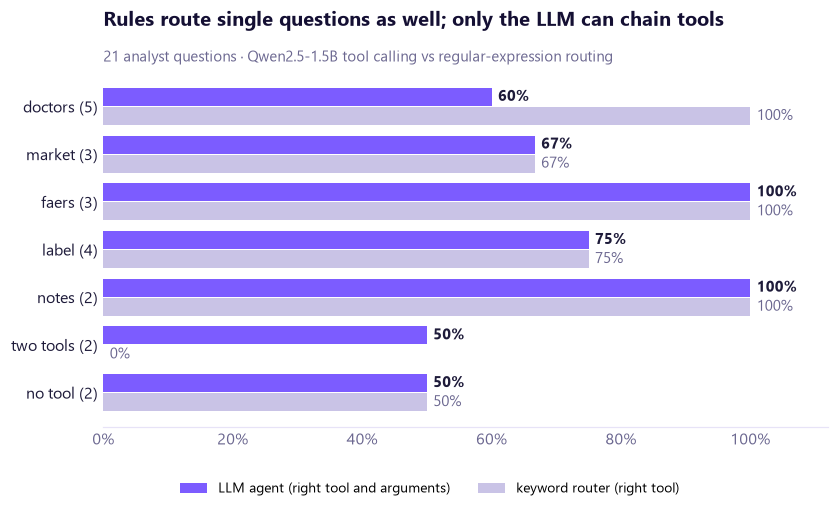

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
y = np.arange(len(by_type))
ax.barh(y - 0.2, by_type["agent_args_ok"], height=0.38, color="#7C5CFF", label="LLM agent (right tool and arguments)")
ax.barh(y + 0.2, by_type["keyword_router_ok"], height=0.38, color=MUTED, label="keyword router (right tool)")
for yi, v in zip(y - 0.2, by_type["agent_args_ok"]): ax.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=9.5, color=TEXT, fontweight="bold")
for yi, v in zip(y + 0.2, by_type["keyword_router_ok"]): ax.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=9.5, color=TEXT_2)
ax.set(yticks=y, yticklabels=[f"{t} ({n})" for t, n in zip(by_type["type"], by_type["questions"])], xlim=(0, 1.12))
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=2, frameon=False, fontsize=9)
ax.set_title("Rules route single questions as well; only the LLM can chain tools")
subtitle(ax, "21 analyst questions · Qwen2.5-1.5B tool calling vs regular-expression routing")
viz.save(fig, "15_1_agent_vs_router")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

On FAERS, notes, label, market and no-tool questions the two are tied. The LLM's advantage is the **two-tool** row (1 of 2 vs none). On the **doctor** questions it picked the right tool every time but got the filters right only 3 of 5 times: it dropped *family practice* for Texas, and used segment **F** (low volume) for *untapped potential*, which is segment **D**.

</div>

In [7]:
bad = sc[~sc["args_ok"]].merge(runs[["question", "steps", "answer"]], on="question")
bad["calls"] = bad["steps"].map(lambda st: "; ".join(f"{s['name']}({json.dumps(s['arguments'])})" for s in st) or "(none)")
show(bad[["type", "question", "calls", "answer"]].assign(answer=bad["answer"].str[:160]), "Questions the agent got wrong")

type,question,calls,answer
doctors,Show the top 3 family practice doctors in Texas by targeting score.,"top_doctors({""state"": ""TX"", ""specialty"": """", ""segment"": """"})",Here are the top 3 family practice doctors in Texas based on their targeting score: 1. **NPI 134•••••••** - Specialty: Family Practice - Rank: 19
doctors,Who are the best untapped-potential doctors in Florida?,"top_doctors({""state"": ""FL"", ""segment"": ""F"", ""n"": 5})","Based on the top 5 untapped-potential doctors in Florida: 1. **NPI 163•••••••** - Rank 76,997, Score 58.9, Segment F, Low Volume, 27 GLP-1 claims, Tirzepatide"
market,How many eligible GLP-1 prescribers are there in New York?,"top_doctors({""state"": ""NY""})","There are **19,639** eligible GLP-1 prescribers in New York. The top 5 by targeting score include: 1. Dr. [Name Hidden] - Internal Medicine, Rank 2, Score 92.4"
label,How long can Trulicity pens stay at room temperature?,(none),None of the available tools provide information on the shelf life of Trulicity pens. I would recommend contacting the manufacturer directly for this specific in
two tools,"Which Ohio endocrinologists should we prioritise, and what is Foundayo's boxed warning?","top_doctors({""state"": ""OH"", ""specialty"": ""Endocrinology""})","Based on the ranking, here are the top 5 Ohio endocrinologists who target GLP-1 drugs: 1. **NPI 179•••••••** - Rank 35, Score 91.4, Segment B, High-value swing"
no tool,What will the GLP-1 market share be in 2030?,market_summary({}),"In 2024, there were approximately 308,303 eligible prescribers and 19,455,666 GLP-1 claims. Tizepatide had a share of 29% among these claims, while Semaglutide"


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Four kinds of failure:
1. **Wrong filter**: Texas without the specialty, Florida with segment F instead of D. Both produce believable lists.
2. **Different but valid path**: the New York count came from `top_doctors` ("19,639 doctors match"), which is the right number, so a strict tool-match score under-counts it.
3. **No tool when one was needed**: for Trulicity storage the model answered *"none of the tools provide this"*, although `label_answer` does. A safe failure (no invented fact), but unhelpful.
4. **A tool where none fits**: for the 2030 forecast it fetched 2024 data. Its answer then says the figures *"do not directly predict future"* market share, which is acceptable behaviour.

</div>

In [8]:
manual = pd.read_csv(C.EVAL_DIR / "nb15_manual_grades.csv")    # every final answer read and graded against the tool data
g = manual.pivot_table(index="type", columns="grade", values="question", aggfunc="size", fill_value=0, sort=False)
g = g.reindex(columns=["correct", "partial", "wrong"], fill_value=0)
display(show(pd.concat([g, g.sum().to_frame("ALL").T]).reset_index().rename(columns={"index": "type"}), "Final answers graded by hand (21 questions)"))
show(manual[manual["grade"] != "correct"][["grade", "question", "note"]], "Why the partial and wrong answers fail")

type,correct,partial,wrong
doctors,3,0,2
market,2,1,0
faers,1,2,0
label,2,0,2
notes,1,1,0
two tools,1,1,0
no tool,2,0,0
ALL,12,5,4


grade,question,note
wrong,Show the top 3 family practice doctors in Texas by targeting score.,"dropped the specialty filter, then presented internal-medicine doctors as family practice"
wrong,Who are the best untapped-potential doctors in Florida?,used segment F (low volume) instead of D (untapped); invented a rationale
partial,What is tirzepatide's share of GLP-1 claims in Louisiana?,44% is right; then mislabels segment counts as drug shares
partial,What side effects are most reported to FAERS for Ozempic?,"counts are for all semaglutide products (FAERS by molecule), presented as Ozempic only"
partial,Top 3 reported reactions for Trulicity in FAERS?,"right three reactions; 'over 10,000 combined' is wrong (about 30,000)"
wrong,Is Wegovy approved to reduce cardiovascular risk?,'80% reduction' misreads hazard ratio 0.80 (= 20% lower risk); drops the tool's review flag; invents source descriptions
wrong,How long can Trulicity pens stay at room temperature?,called no tool and said no tool has this (label_answer does); a safe failure
partial,What do doctors say about cost and insurance in the visit notes?,cost theme right but mixes in unrelated headache and safety details
partial,"Which Ohio endocrinologists should we prioritise, and what is Foundayo's boxed warning?",doctor list right; silently skipped the boxed-warning half


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

**12 correct, 5 partial, 4 wrong.** Reading the answers finds errors the tool-choice score can't see:
- **Misread tool output**: Louisiana's segment counts presented as drug shares; Trulicity's three reactions "over 10,000 combined" (about 30,000)
- **Over-claiming**: semaglutide-wide FAERS counts presented as Ozempic only
- **The worst one, Wegovy**: *"reduces MACE by 80%"*. The label gives a hazard ratio of **0.80**, which means a **20% lower** risk (8.0% vs 6.5% of patients). The error was made inside `label_answer`, which **flagged it for review**. The agent then dropped the flag and added invented descriptions of the sources.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## D · Are the numbers in the answers real?

</div>

In [9]:
NUM = re.compile(r"\d[\d,]*(?:\.\d+)?%?")
def numbers_check(answer, steps, question):
    tool_text = " ".join(s["result"] for s in steps).replace(",", "") + " " + question.replace(",", "")
    nums = [n.replace(",", "") for n in NUM.findall(answer)]
    nums = [n for n in nums if not (n.isdigit() and int(n) <= 10)]       # skip list numbering 1., 2., …
    missing = [n for n in nums if n not in tool_text]
    return len(nums), missing
rows = []
for r in runs.itertuples():
    n, miss = numbers_check(r.answer, r.steps, r.question)
    rows.append({"question": r.question, "numbers in answer": n, "not found in any tool result": ", ".join(miss)})
nums = pd.DataFrame(rows)
grounded = 1 - nums["not found in any tool result"].str.len().gt(0).sum() / max((nums["numbers in answer"] > 0).sum(), 1)
total_n = nums["numbers in answer"].sum(); missing_n = nums["not found in any tool result"].str.split(", ").map(lambda x: len([v for v in x if v])).sum()
display(show(nums[nums["numbers in answer"] > 0], f"{total_n} numbers in the answers · {missing_n} not found in the tool results"))

question,numbers in answer,not found in any tool result
Which endocrinologists in Ohio should we prioritise for Foundayo?,12,
Show the top 3 family practice doctors in Texas by targeting score.,12,
Who are the best untapped-potential doctors in Florida?,13,
List the top cardiologists in California for GLP-1 targeting.,11,
Where should a new rep in Georgia start? Who are the best GLP-1 prescribers there?,15,
What is tirzepatide's share of GLP-1 claims in Louisiana?,4,
How many eligible GLP-1 prescribers are there in New York?,10,
What share of US GLP-1 claims is oral semaglutide?,2,
What side effects are most reported to FAERS for Ozempic?,10,
How many FAERS reports mention orforglipron so far?,3,


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

**127 of 128 numbers** in the answers appear in a tool result. The one exception is Trulicity's *"over 10,000"*, a number the LLM made up. So the LLM almost never invents numbers when tools provide them.

But this check **missed the worst error**: *"80%"* *is* in a tool result, because the `label_answer` tool (itself an LLM) produced it. **A hallucination inside one tool becomes a "grounded" fact for the next step.** Grounding checks must go back to the original source documents, not stop at intermediate LLM text.

</div>

In [10]:
w = runs[runs["question"].str.contains("Wegovy")].iloc[0]
print("TOOL RESULT (label_answer):")
print(" ", w["steps"][0]["result"][:260])
print()
print("WHAT THE USER NOW SEES (agent answer + code-enforced provenance):")
print(" ", A.finalize(w["answer"], w["steps"])[:700])

TOOL RESULT (label_answer):
  Yes, Wegovy reduces the risk of major adverse cardiovascular events (MACE) by 80% compared to placebo in adults with established cardiovascular disease and obesity or overweight [1]. (flagged for human review: not fully supported)
Sources: [1] Wegovy label · 1

WHAT THE USER NOW SEES (agent answer + code-enforced provenance):
  ⚠️ Verify before use: the label_answer result behind this answer was flagged as not fully supported by its sources.

Yes, Wegovy is approved to reduce cardiovascular risk by reducing the risk of major adverse cardiovascular events (MACE) by 80% compared to placebo in adults with established cardiovascular disease and obesity or overweight according to its FDA label. This information comes from the following sources:

1. **Indications and Usage**: Wegovy is indicated for weight loss in adult patients who have been previously treated with or are intolerant to other anti-obesity agents.
   
2. **Clinical Studies**: The Wegovy label inc

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

The fix is **code, not prompting**: `finalize()` adds the list of tools used and carries forward any warning a tool raised. The LLM can rephrase a result, but it can no longer remove the *"verify before use"* flag. The same principle as notebook 14: **mandatory content is added by code.**

</div>

In [11]:
for q in ["What will the GLP-1 market share be in 2030?", "What is the weather in Chicago today?"]:
    r = runs[runs["question"] == q].iloc[0]
    print("Q:", q, "\n  tools:", [s["name"] for s in r["steps"]] or "(none)", "\n  A:", r["answer"][:400], "\n")

Q: What will the GLP-1 market share be in 2030? 
  tools: ['market_summary'] 
  A: In 2024, there were approximately 308,303 eligible prescribers and 19,455,666 GLP-1 claims. Tizepatide had a share of 29% among these claims, while Semaglutide (Rybelsus) accounted for 4.6% of GLP-1 claims. The distribution across segments was as follows:

- Segment A: 10,982 doctors
- Segment B: 28,618 doctors
- Segment C: 19,950 doctors
- Segment D: 20,181 doctors
- Segment E: 69,730 doctors
- S 

Q: What is the weather in Chicago today? 
  tools: (none) 
  A: I'm sorry, but I don't have the capability to provide current weather information. Please check a reliable weather website or app for the latest updates on the weather in Chicago. 



<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Both out-of-scope questions are handled safely: the weather question gets a polite *"I can't"* with no tool call. The 2030 question gets 2024 context plus an explicit disclaimer instead of an invented forecast.

</div>

In [12]:
C.save_metrics("nb15_agent", {
    "llm": "Qwen/Qwen2.5-1.5B-Instruct", "questions": len(sc), "tool_choice_ok": float(sc["tools_ok"].mean()),
    "tool_and_args_ok": float(sc["args_ok"].mean()), "keyword_router_ok": float(sc["router ok"].mean()),
    "by_type": by_type.to_dict("records"), "numbers_in_answers": int(total_n), "numbers_not_in_tool_results": int(missing_n),
    "median_seconds": float(runs["seconds"].median()),
})
print("saved reports/evaluation/nb15_agent.json")

saved reports/evaluation/nb15_agent.json


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## E · Summary

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. **21 questions, one grader.** The rates move 5 points per question. A larger, independently written test set is the next step.
2. **The keyword baseline is optimistic** (rules written after seeing the questions).
3. **Small model, slow loop**: ~2 minutes per question on CPU. Long tool descriptions are re-read at every step. A 7B+ model or an API model would be faster and follow the *"answer every part"* and *"at most 4 sentences"* rules better.
4. **No memory or planning**: each question starts fresh, one tool at a time, max 3 calls.
5. **Data limits flow through**: FAERS is by molecule and voluntary, Part D is Medicare-only 2024, visit notes are synthetic. The agent is only as good as its tools.
6. Not a compliance system: the guard flags and the masked NPIs demonstrate the ideas, they are not validated controls.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** an Ask-AI agent on free local tools. The LLM picks among 5 tools and fills their arguments; code computes every number (127 of 128 numbers traceable). It chooses the right tool **81%** of the time, but the right tool *with the right filters* only **71%**, and 12 of 21 final answers are fully correct. The most instructive failure was a hallucination inside one tool (*"80%"* for HR 0.80) that the agent passed on as fact, now caught by code-enforced provenance (`finalize`).
**Next:** notebook 17 (evaluation and guardrails report), pulling notebooks 07–15 into one scorecard. Then the Ask-AI page in the app.

**Check your understanding**
- *What is an agent?* An LLM in a loop that chooses actions (tool calls), observes the results and decides the next step: reason → act → observe.
- *How does function calling work?* Tools are described as JSON schemas (here generated from docstrings). The model emits a structured call, code executes it and returns the result as a message.
- *When should you NOT use an LLM to route?* When a few rules do as well: here a keyword router tied the agent on single-tool questions. Use the LLM for argument extraction and multi-step questions.
- *How do you evaluate an agent?* Per step: tool choice, arguments, number grounding, then the final answer read by a human. A correct tool with a wrong filter is the silent failure.
- *What is error propagation in agents?* One component's hallucination becomes the next component's "fact" (the 80% case). Check against original sources, and carry warnings forward in code.
- *How do you keep numbers trustworthy?* Never let the LLM compute or remember them: tools compute, the LLM only phrases, and a checker verifies each number appears in tool output.

</div>